# JSE Portfolio Risk & Return Analysis
**Author:** Tamuka Lee Bubu

**Question:** How would an equal-weight portfolio compare with minimum-variance and maximum-Sharpe portfolios of 10 JSE Top 40 stocks, and does optimisation still help on data the optimiser has not seen?

**Method:** daily returns, risk metrics, correlation, mean-variance optimisation (long-only), efficient frontier, drawdowns, benchmark comparison, and an out-of-sample test.

**CFA Level 1 links:** Quantitative Methods (returns, statistics), Portfolio Management (risk/return, diversification, Sharpe, efficient frontier).

In [1]:
!pip install yfinance -q
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from scipy.optimize import minimize
import os
os.makedirs('images', exist_ok=True)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

## 1. Configuration
The risk-free rate is an assumption (8% p.a., held constant over the whole period).

In [2]:
TICKERS = ['NPN.JO','SBK.JO','FSR.JO','AGL.JO','SOL.JO','MTN.JO','SHP.JO','BVT.JO','BTI.JO','GFI.JO']
BENCHMARK = 'STX40.JO'      # Satrix 40 ETF, used as a proxy for the JSE Top 40
START = '2021-01-01'
END = '2026-10-29'                 # End date
RF = 0.08                   # annual risk-free rate (assumed 8%, held constant)
TRADING_DAYS = 252

## 2. Download and clean data

In [3]:
raw = yf.download(TICKERS + [BENCHMARK], start=START, end=END, auto_adjust=True, progress=False)['Close']
print('Downloaded:', list(raw.columns))
missing = [t for t in TICKERS + [BENCHMARK] if t not in raw.columns or raw[t].dropna().empty]
print('Missing/empty tickers:', missing)

# Which ticker starts latest? (this sets the start of your usable window)
print('\nFirst valid date per ticker:')
print(raw.apply(lambda s: s.first_valid_index()))

prices = raw.dropna(how='all').ffill().dropna()

# Data cleaning: flag any price more than 40% away from its 5-day median
med = prices.rolling(5, center=True, min_periods=1).median()
bad = (prices / med - 1).abs() > 0.40
print('\nBad price points removed:')
print(bad.sum()[bad.sum() > 0])
prices = prices.mask(bad).ffill()

print('\n', prices.shape, prices.index.min().date(), 'to', prices.index.max().date())
prices.head()

Downloaded: ['AGL.JO', 'BTI.JO', 'BVT.JO', 'FSR.JO', 'GFI.JO', 'MTN.JO', 'NPN.JO', 'SBK.JO', 'SHP.JO', 'SOL.JO', 'STX40.JO']
Missing/empty tickers: []

First valid date per ticker:
Ticker
AGL.JO     2021-01-04
BTI.JO     2021-01-04
BVT.JO     2021-01-04
FSR.JO     2021-01-04
GFI.JO     2021-01-04
MTN.JO     2021-01-04
NPN.JO     2021-01-04
SBK.JO     2021-01-04
SHP.JO     2021-01-04
SOL.JO     2021-01-04
STX40.JO   2021-01-04
dtype: datetime64[ns]

Bad price points removed:
Ticker
SBK.JO      1
STX40.JO    1
dtype: int64

 (1455, 11) 2021-01-04 to 2026-10-28


Ticker,AGL.JO,BTI.JO,BVT.JO,FSR.JO,GFI.JO,MTN.JO,NPN.JO,SBK.JO,SHP.JO,SOL.JO,STX40.JO
Date,,,,,,,,,,,
2021-01-04,50179.683594,54881.078125,15492.387695,4932.402832,14958.335938,6103.594238,60729.472656,12387.509766,13070.954102,13278.392578,5539.893066
2021-01-05,51138.859375,56673.925781,15048.351562,4793.897949,15438.319336,6254.386719,62323.621094,12174.311523,12731.527344,13183.510742,5593.499512
2021-01-06,54668.835938,57604.210938,15380.628906,4860.658203,15018.207031,6514.029297,62010.269531,12353.639648,12978.113281,14364.035156,5683.264648
2021-01-07,57186.906250,58171.941406,15418.548828,5020.089355,14837.589844,6873.533691,60265.546875,12664.471680,13298.571289,16079.888672,5795.687988
2021-01-08,56863.605469,57899.042969,15701.933594,5212.404297,14409.496094,6785.654785,61395.773438,13068.953125,13810.708008,16812.970703,5837.217285


Note: Yahoo quotes JSE prices in South African cents (ZAc). This does not affect returns, which are percentage changes.

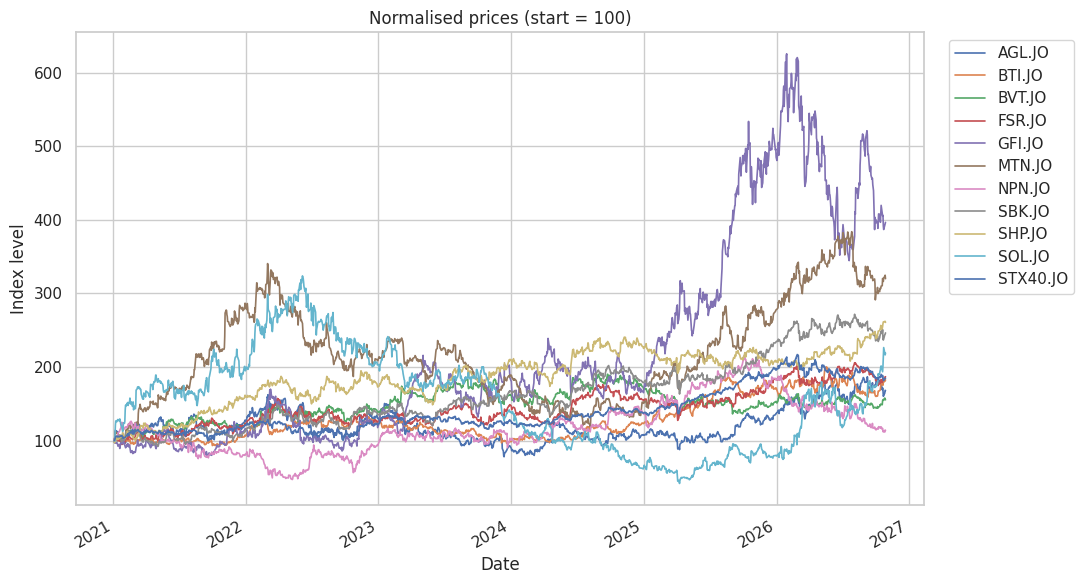

In [4]:
rets = prices.pct_change().dropna()
asset_rets = rets[[t for t in TICKERS if t in rets.columns]]
bench_rets = rets[BENCHMARK]

# Normalised price chart
(prices / prices.iloc[0] * 100).plot(figsize=(11,6), lw=1.2)
plt.title('Normalised prices (start = 100)'); plt.ylabel('Index level')
plt.legend(bbox_to_anchor=(1.02,1), loc='upper left')
plt.tight_layout(); plt.savefig('images/normalised_prices.png', dpi=150); plt.show()

## 3. Individual stock statistics

In [5]:
def ann_return(r): return (1 + r).prod() ** (TRADING_DAYS / len(r)) - 1
def ann_vol(r): return r.std() * np.sqrt(TRADING_DAYS)
def sharpe(r, rf=RF): return (ann_return(r) - rf) / ann_vol(r)

stats = pd.DataFrame({
    'Ann. return': asset_rets.apply(ann_return),
    'Ann. volatility': asset_rets.apply(ann_vol),
    'Sharpe': asset_rets.apply(sharpe),
})
stats.sort_values('Sharpe', ascending=False).style.format('{:.2%}', subset=['Ann. return','Ann. volatility']).format('{:.2f}', subset=['Sharpe'])

,Ann. return,Ann. volatility,Sharpe
Ticker,,,
SHP.JO,18.05%,24.34%,0.41
MTN.JO,22.33%,35.96%,0.40
GFI.JO,26.96%,49.37%,0.38
SBK.JO,16.91%,25.70%,0.35
FSR.JO,11.43%,25.90%,0.13
SOL.JO,14.53%,51.04%,0.13
BTI.JO,10.96%,23.24%,0.13
AGL.JO,9.40%,38.93%,0.04
BVT.JO,7.93%,25.49%,-0.00


## 4. Correlation and diversification

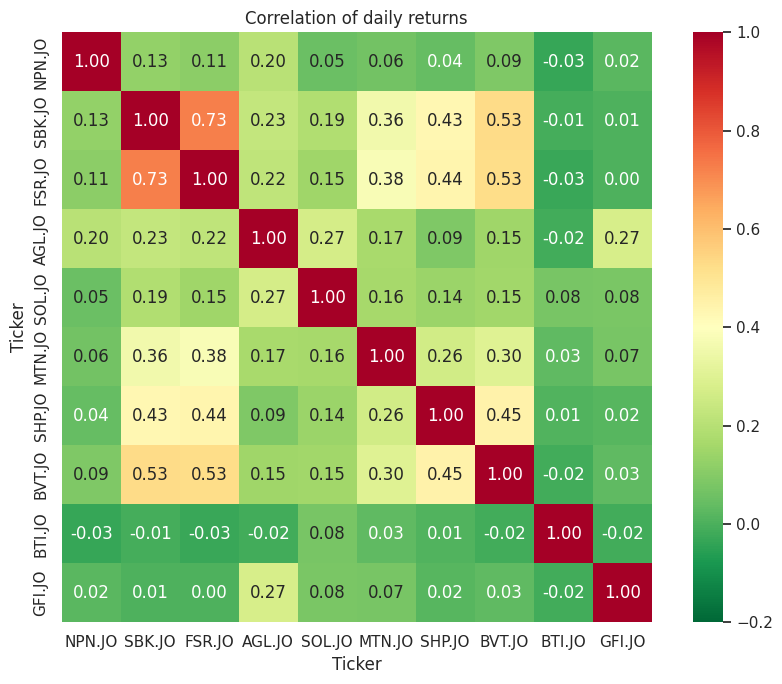

In [6]:
plt.figure(figsize=(9,7))
sns.heatmap(asset_rets.corr(), annot=True, fmt='.2f', cmap='RdYlGn_r', vmin=-0.2, vmax=1, square=True)
plt.title('Correlation of daily returns')
plt.tight_layout(); plt.savefig('images/correlation_heatmap.png', dpi=150); plt.show()

## 5. Portfolio construction
Three long-only, fully invested portfolios:
1. **Equal weight**: 1/N in each stock
2. **Minimum variance**: lowest possible volatility
3. **Maximum Sharpe**: highest risk-adjusted return (the tangency portfolio)

Optimisation uses `scipy` (SLSQP) with weights between 0 and 40% per stock, which avoids extreme single-stock bets.

In [7]:
def port_perf(w, mu, cov):
    return w @ mu, np.sqrt(w @ cov @ w)

def optimise(mu, cov, objective, max_w=0.40):
    n = len(mu)
    cons = ({'type': 'eq', 'fun': lambda w: w.sum() - 1},)
    bnds = [(0, max_w)] * n
    w0 = np.repeat(1/n, n)
    res = minimize(objective, w0, method='SLSQP', bounds=bnds, constraints=cons)
    return res.x

def build_portfolios(r):
    mu = r.mean().values * TRADING_DAYS
    cov = r.cov().values * TRADING_DAYS
    n = len(mu)
    w_eq = np.repeat(1/n, n)
    w_mv = optimise(mu, cov, lambda w: w @ cov @ w)
    w_ms = optimise(mu, cov, lambda w: -((w @ mu - RF) / np.sqrt(w @ cov @ w)))
    return pd.DataFrame({'Equal weight': w_eq, 'Min variance': w_mv, 'Max Sharpe': w_ms}, index=r.columns)

# Full-sample weights (in-sample: for illustration only)
weights = build_portfolios(asset_rets)
weights.style.format('{:.1%}')

,Equal weight,Min variance,Max Sharpe
Ticker,,,
NPN.JO,10.0%,8.2%,0.3%
SBK.JO,10.0%,6.1%,11.9%
FSR.JO,10.0%,7.1%,0.0%
AGL.JO,10.0%,4.2%,0.0%
SOL.JO,10.0%,0.9%,7.4%
MTN.JO,10.0%,2.8%,17.3%
SHP.JO,10.0%,17.3%,24.0%
BVT.JO,10.0%,11.3%,0.0%
BTI.JO,10.0%,36.0%,17.6%


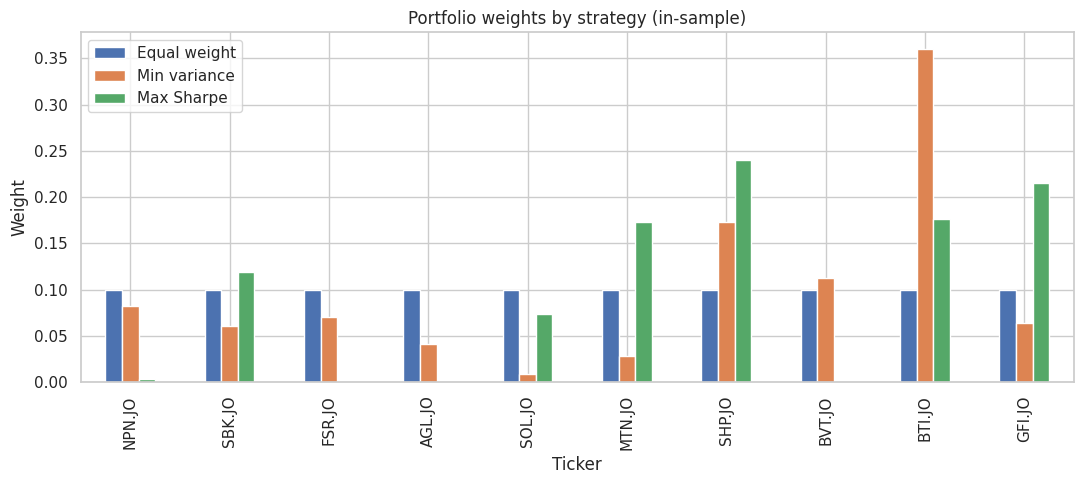

In [8]:
weights.plot(kind='bar', figsize=(11,5))
plt.title('Portfolio weights by strategy (in-sample)'); plt.ylabel('Weight')
plt.tight_layout(); plt.savefig('images/weights.png', dpi=150); plt.show()

## 6. Efficient frontier

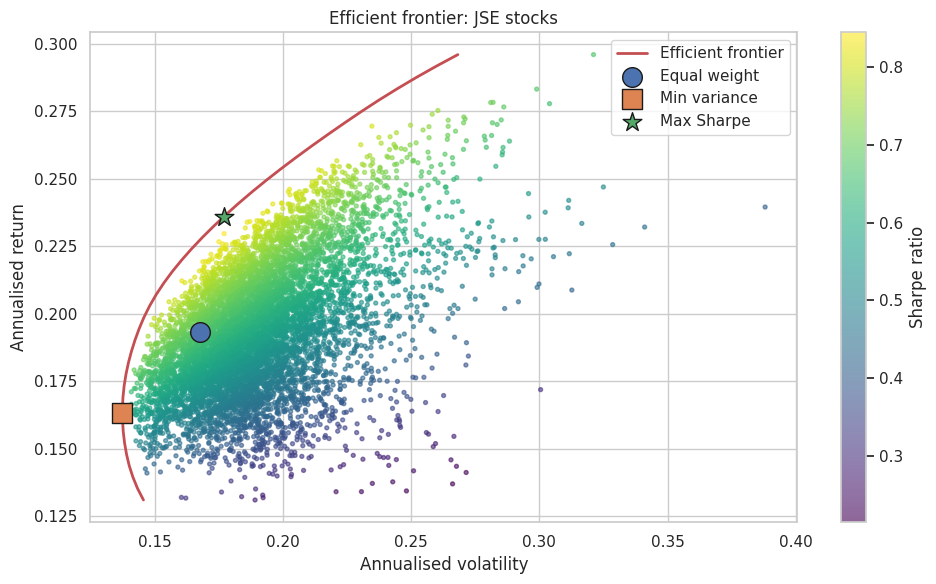

In [9]:
mu = asset_rets.mean().values * TRADING_DAYS
cov = asset_rets.cov().values * TRADING_DAYS
n = len(mu)

# Random long-only portfolios
rng = np.random.default_rng(42)
W = rng.dirichlet(np.ones(n), 8000)
rp = W @ mu
vp = np.sqrt(np.einsum('ij,jk,ik->i', W, cov, W))
sp = (rp - RF) / vp

# Frontier by minimising variance for target returns
targets = np.linspace(rp.min(), rp.max(), 40)
front = []
for t in targets:
    cons = ({'type':'eq','fun':lambda w: w.sum()-1}, {'type':'eq','fun':lambda w,t=t: w @ mu - t})
    res = minimize(lambda w: w @ cov @ w, np.repeat(1/n,n), method='SLSQP', bounds=[(0,1)]*n, constraints=cons)
    if res.success: front.append((np.sqrt(res.fun), t))
front = np.array(front)

plt.figure(figsize=(10,6))
sc = plt.scatter(vp, rp, c=sp, cmap='viridis', s=8, alpha=0.6)
plt.colorbar(sc, label='Sharpe ratio')
plt.plot(front[:,0], front[:,1], 'r-', lw=2, label='Efficient frontier')
for name, marker in zip(weights.columns, ['o','s','*']):
    r_, v_ = port_perf(weights[name].values, mu, cov)
    plt.scatter(v_, r_, s=200, marker=marker, edgecolor='k', label=name, zorder=5)
plt.xlabel('Annualised volatility'); plt.ylabel('Annualised return')
plt.title('Efficient frontier: JSE stocks'); plt.legend()
plt.tight_layout(); plt.savefig('images/efficient_frontier.png', dpi=150); plt.show()

## 7. Out-of-sample test
In-sample optimisation flatters the optimiser because the weights are fitted to the same data they are judged on. To test honestly:
- **Train** on the first 60% of the data and compute weights
- **Test** by holding those weights fixed over the remaining 40%

In [10]:
split = int(len(asset_rets) * 0.6)
train, test = asset_rets.iloc[:split], asset_rets.iloc[split:]
w_train = build_portfolios(train)
print('Train:', train.index[0].date(), 'to', train.index[-1].date())
print('Test: ', test.index[0].date(), 'to', test.index[-1].date())

oos = pd.DataFrame({c: test @ w_train[c] for c in w_train.columns})
oos['Benchmark (STX40)'] = bench_rets.loc[test.index]

def max_drawdown(r):
    cum = (1 + r).cumprod()
    return (cum / cum.cummax() - 1).min()

def summary(df):
    out = pd.DataFrame({
        'Ann. return': df.apply(ann_return),
        'Ann. volatility': df.apply(ann_vol),
        'Sharpe': df.apply(sharpe),
        'Max drawdown': df.apply(max_drawdown),
    })
    return out

oos_summary = summary(oos)
oos_summary.style.format('{:.2%}', subset=['Ann. return','Ann. volatility','Max drawdown']).format('{:.2f}', subset=['Sharpe'])

Train: 2021-01-05 to 2024-07-02
Test:  2024-07-03 to 2026-10-28


,Ann. return,Ann. volatility,Sharpe,Max drawdown
Equal weight,24.77%,14.99%,1.12,-11.18%
Min variance,20.54%,12.65%,0.99,-9.65%
Max Sharpe,14.93%,17.82%,0.39,-11.46%
Benchmark (STX40),15.30%,16.93%,0.43,-16.30%


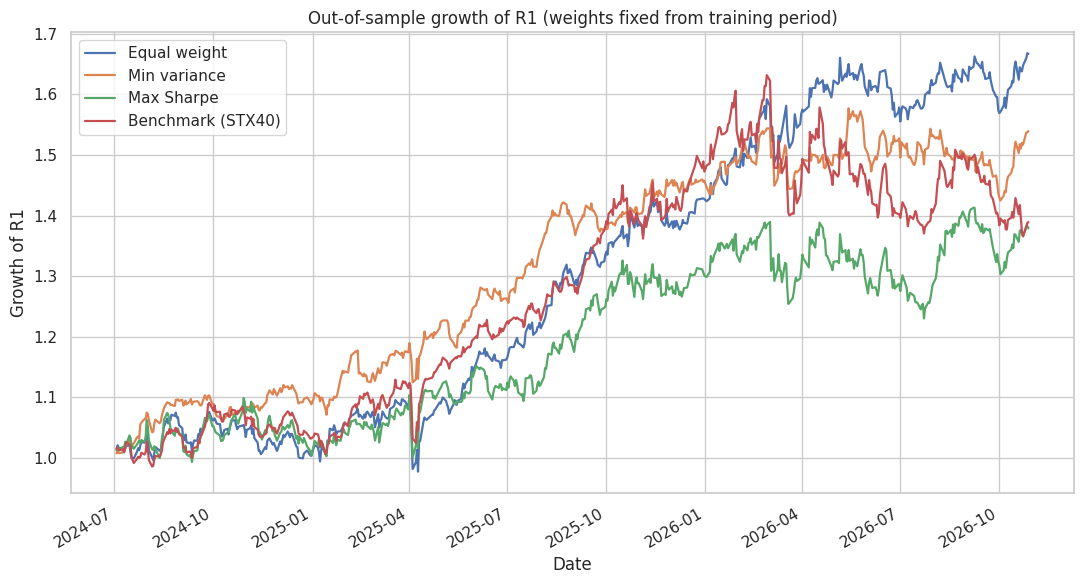

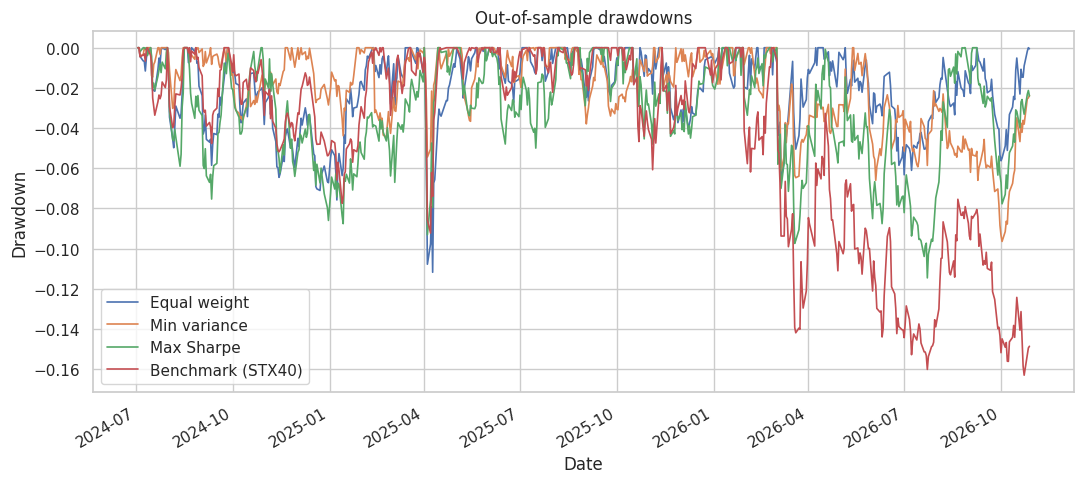

In [11]:
(1 + oos).cumprod().plot(figsize=(11,6), lw=1.6)
plt.title('Out-of-sample growth of R1 (weights fixed from training period)')
plt.ylabel('Growth of R1')
plt.tight_layout(); plt.savefig('images/out_of_sample_growth.png', dpi=150); plt.show()

dd = (1 + oos).cumprod()
dd = dd / dd.cummax() - 1
dd.plot(figsize=(11,5), lw=1.2)
plt.title('Out-of-sample drawdowns'); plt.ylabel('Drawdown')
plt.tight_layout(); plt.savefig('images/drawdowns.png', dpi=150); plt.show()

## 8. Risk measures and beta vs benchmark

In [12]:
def beta(r, b):
    return np.cov(r, b)[0,1] / np.var(b, ddof=1)

risk = pd.DataFrame({
    'Beta vs STX40': [beta(oos[c], oos['Benchmark (STX40)']) for c in oos.columns],
    'Daily VaR 95% (historical)': [oos[c].quantile(0.05) for c in oos.columns],
}, index=oos.columns)
risk.style.format({'Beta vs STX40': '{:.2f}', 'Daily VaR 95% (historical)': '{:.2%}'})

,Beta vs STX40,Daily VaR 95% (historical)
Equal weight,0.69,-1.36%
Min variance,0.41,-1.28%
Max Sharpe,0.79,-1.74%
Benchmark (STX40),1.00,-1.62%


## 9. Findings
- **Best out-of-sample:** equal weight (Sharpe 1.12), followed by minimum variance (0.99). Maximum Sharpe (0.39) did slightly worse than the STX40 benchmark (0.43).
- **Overfitting:** maximum Sharpe had the best Sharpe in-sample (0.86) and the worst out-of-sample (0.39). Its weights were unstable, with BTI and MTN moving from 0% in training to about 17% each on the full sample.
- **Risk:** minimum variance had the lowest volatility (12.65%) and smallest drawdown (-9.65%). Max Sharpe had a beta of 0.79 but a worse VaR than the benchmark, because it held concentrated stock-specific risk.
- **Correlation:** SBK and FSR were the most correlated pair (0.73). BTI, GFI and NPN were close to uncorrelated with most others, which is where much of the diversification came from.
- **Caution:** the test window is only about 2.3 years, so the gap between equal weight and minimum variance is within noise.

## 10. Limitations and next steps
- Historical returns are a noisy estimator of future returns; mean-variance optimisation is highly sensitive to the return inputs
- No transaction costs, taxes or rebalancing; weights are static
- Only 10 stocks and one market regime in the sample window
- Risk-free rate is held constant
- **Next steps:** add a rolling rebalance backtest, shrinkage covariance (Ledoit-Wolf), CAPM alpha/beta regression, and a Black-Litterman view

## 11. In-sample vs out-of-sample check
The same three portfolios evaluated on the training period (the data their weights were fitted on), plus the training weights and each portfolio's worst out-of-sample day. Compare with Section 7 to see the overfitting gap.

In [13]:
ins = pd.DataFrame({c: train @ w_train[c] for c in w_train.columns})
print(summary(ins))
print(w_train.round(3))
print(oos.idxmin())
print(oos.min())

              Ann. return  Ann. volatility    Sharpe  Max drawdown
Equal weight     0.163326         0.178582  0.466598     -0.153107
Min variance     0.142549         0.145423  0.430116     -0.097546
Max Sharpe       0.248700         0.195794  0.861622     -0.151163
        Equal weight  Min variance  Max Sharpe
Ticker                                        
NPN.JO           0.1         0.070       0.062
SBK.JO           0.1         0.077       0.101
FSR.JO           0.1         0.069       0.000
AGL.JO           0.1         0.029       0.000
SOL.JO           0.1         0.000       0.000
MTN.JO           0.1         0.023       0.000
SHP.JO           0.1         0.153       0.400
BVT.JO           0.1         0.116       0.219
BTI.JO           0.1         0.385       0.000
GFI.JO           0.1         0.079       0.219
Equal weight        2025-04-04
Min variance        2025-02-13
Max Sharpe          2026-03-03
Benchmark (STX40)   2025-04-04
dtype: datetime64[ns]
Equal weight        -0